# 5 · Fat tails and tail dependence: EVT and copulas
**Extreme value theory.** The peaks-over-threshold method fits a generalised Pareto distribution to losses above the 95th percentile and gives closed-form VaR and Expected Shortfall (McNeil and Frey, 2000). It is compared with Normal, Student-t and historical estimates.

**Copulas.** Correlation describes average co-movement. What matters in a crisis is whether assets crash *together*. Fitting copulas to rank-transformed returns separates that joint-tail behaviour from the marginals. The Gaussian copula has zero tail dependence by construction; Student-t has symmetric tail dependence; Clayton has lower-tail and Gumbel upper-tail dependence.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)
from fineco import data
from fineco import tails

In [2]:
r = data.log_returns(data.load_prices())
pd.concat({c: tails.var_es_table(r[c], p=0.99) for c in r}, names=["asset", "method"])

VaR 99%  ES 99%
asset     method                        
bitcoin   Normal           9.328  10.698
          Student-t       12.099  20.250
          Historical      12.102  16.978
          EVT (POT-GPD)   11.812  17.200
cac40_etf Normal           2.674   3.067
          Student-t        3.065   4.522
          Historical       3.562   4.892
          EVT (POT-GPD)    3.392   4.943
gold_etf  Normal           2.472   2.839
          Student-t        2.923   4.292
          Historical       3.168   4.292
          EVT (POT-GPD)    3.018   4.416
sp500     Normal           2.762   3.171
          Student-t        3.205   5.060
          Historical       3.428   5.165
          EVT (POT-GPD)    3.541   5.222

threshold q=0.900: u=1.19%, xi=0.206, n_u=220
threshold q=0.950: u=1.76%, xi=0.220, n_u=110
threshold q=0.975: u=2.48%, xi=0.251, n_u=55


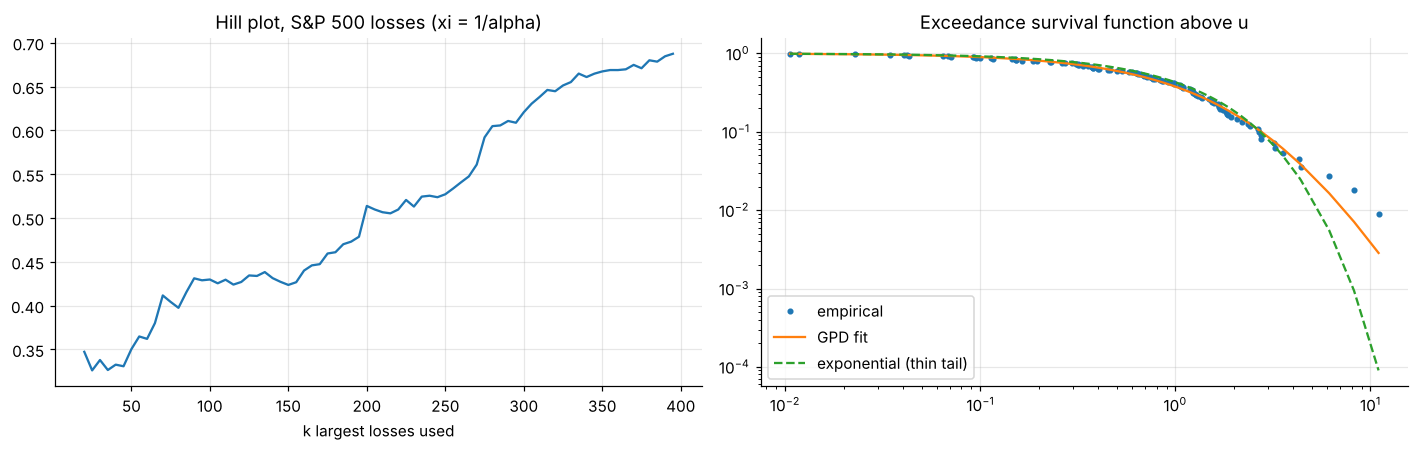

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
L = -100 * r["sp500"].values
ks = np.arange(20, 400, 5)
axes[0].plot(ks, [tails.hill_estimator(L, k) for k in ks]); axes[0].set_title("Hill plot, S&P 500 losses (xi = 1/alpha)")
axes[0].set_xlabel("k largest losses used")
for q in [0.90, 0.95, 0.975]:
    f = tails.fit_pot(L, q); print(f"threshold q={q:.3f}: u={f['u']:.2f}%, xi={f['xi']:.3f}, n_u={f['n_u']}")
f = tails.fit_pot(L, 0.95)
from scipy import stats
exc = np.sort(L[L > f["u"]] - f["u"])
emp = 1 - np.arange(1, len(exc) + 1) / (len(exc) + 1)
axes[1].loglog(exc, emp, ".", label="empirical")
axes[1].loglog(exc, stats.genpareto.sf(exc, f["xi"], scale=f["beta"]), label="GPD fit")
axes[1].loglog(exc, stats.expon.sf(exc, scale=exc.mean()), "--", label="exponential (thin tail)")
axes[1].set_title("Exceedance survival function above u"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "05_evt.png", bbox_inches="tight"); plt.show()

In [4]:
pairs = [("cac40_etf", "sp500"), ("bitcoin", "sp500"), ("gold_etf", "sp500"), ("gold_etf", "bitcoin")]
tabs, emp = {}, {}
for a, b in pairs:
    u = tails.pseudo_obs(r[[a, b]])
    tabs[f"{a} / {b}"] = tails.fit_copulas(u)
    emp[f"{a} / {b}"] = dict(zip(["empirical lower 5%", "empirical upper 5%"], tails.empirical_tail_dependence(u)))
pd.concat(tabs, names=["pair", "copula"])

param   loglik lower_tail  \
pair               copula                                              
cac40_etf / sp500  Student-t   rho=0.513, nu=3.7  401.889       0.28   
                   Gumbel            theta=1.500  336.181        0.0   
                   Gaussian            rho=0.506  322.144        0.0   
                   Clayton           theta=0.806  295.949      0.423   
bitcoin / sp500    Student-t   rho=0.283, nu=9.7   99.864      0.033   
                   Clayton           theta=0.375   91.264      0.157   
                   Gaussian            rho=0.279   88.227        0.0   
                   Gumbel            theta=1.184   70.293        0.0   
gold_etf / sp500   Student-t   rho=0.119, nu=5.0   51.346      0.073   
                   Gumbel            theta=1.086   26.509        0.0   
                   Clayton           theta=0.156     21.1      0.012   
                   Gaussian            rho=0.122   16.266        0.0   
gold_etf / bitcoin Student-t  rho=0.141, nu=17.7    25.09      0.001   
                   Gaussian            rho=0.140   21.648        0.0   
                   Gumbel            theta=1.086   21.223        0.0   
                   Clayton           theta=0.138   16.053      0.006   

                             upper_tail      AIC  
pair               copula                         
cac40_etf / sp500  Student-t       0.28 -799.779  
                   Gumbel         0.412 -670.363  
                   Gaussian         0.0 -642.288  
                   Clayton          0.0 -589.897  
bitcoin / sp500    Student-t      0.033 -195.728  
                   Clayton          0.0 -180.529  
                   Gaussian         0.0 -174.453  
                   Gumbel         0.205 -138.585  
gold_etf / sp500   Student-t      0.073  -98.692  
                   Gumbel         0.107  -51.019  
                   Clayton          0.0  -40.200  
                   Gaussian         0.0  -30.532  
gold_etf / bitcoin Student-t      0.001  -46.180  
                   Gaussian         0.0  -41.296  
                   Gumbel         0.107  -40.445  
                   Clayton          0.0  -30.107

In [5]:
summary = pd.DataFrame({p: {"best copula (AIC)": t.index[0], "best-fit parameters": t.iloc[0]["param"],
                            "t-copula tail dependence": float(t.loc["Student-t", "lower_tail"])} for p, t in tabs.items()}).T
summary.join(pd.DataFrame(emp).T)

,best copula (AIC),best-fit parameters,t-copula tail dependence,empirical lower 5%,empirical upper 5%
cac40_etf / sp500,Student-t,"rho=0.513, nu=3.7",0.28,0.364,0.300
bitcoin / sp500,Student-t,"rho=0.283, nu=9.7",0.033,0.218,0.136
gold_etf / sp500,Student-t,"rho=0.119, nu=5.0",0.073,0.100,0.146
gold_etf / bitcoin,Student-t,"rho=0.141, nu=17.7",0.001,0.064,0.100


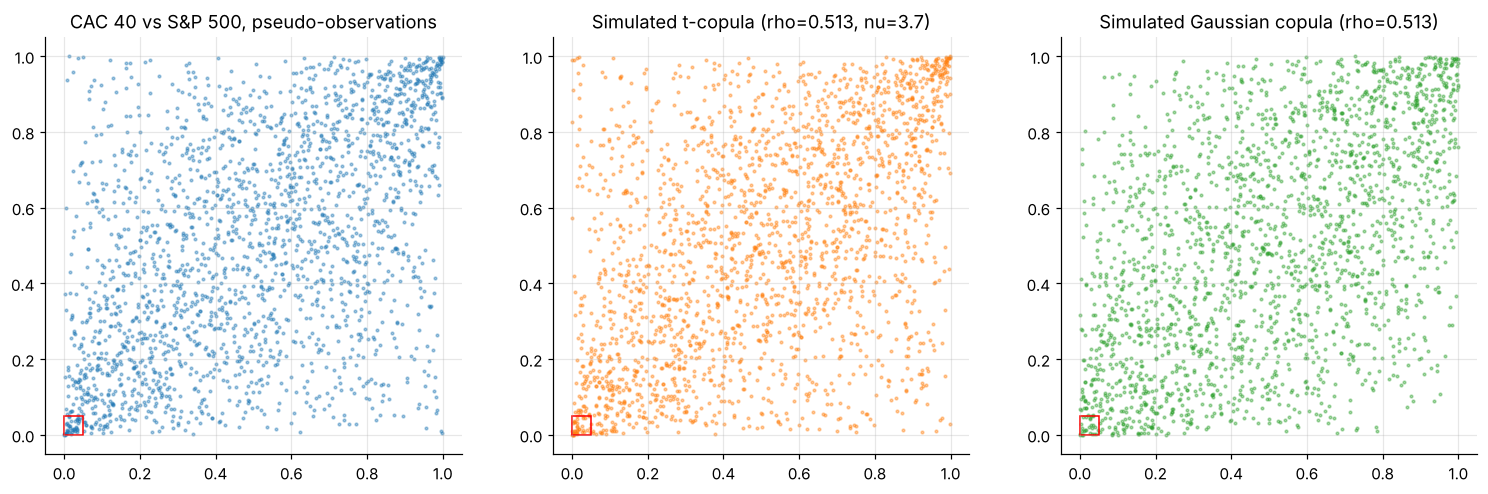

joint crashes in the red box (both below 5th pct): {'data': 40, 't-copula': 37, 'Gaussian': 25}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
u = tails.pseudo_obs(r[["cac40_etf", "sp500"]])
axes[0].scatter(u[:, 0], u[:, 1], s=3, alpha=.4); axes[0].set_title("CAC 40 vs S&P 500, pseudo-observations")
t = tabs["cac40_etf / sp500"].loc["Student-t", "param"]
rho, nu = [float(x.split("=")[1]) for x in t.split(",")]
sim = tails.sample_t_copula(rho, nu, len(u), seed=1)
axes[1].scatter(sim[:, 0], sim[:, 1], s=3, alpha=.4, c="C1"); axes[1].set_title(f"Simulated t-copula ({t})")
rng = np.random.default_rng(1); z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], len(u)); g = stats.norm.cdf(z)
axes[2].scatter(g[:, 0], g[:, 1], s=3, alpha=.4, c="C2"); axes[2].set_title(f"Simulated Gaussian copula (rho={rho})")
for ax in axes:
    ax.add_patch(plt.Rectangle((0, 0), .05, .05, fill=False, ec="r")); ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(FIG / "05_copulas.png", bbox_inches="tight"); plt.show()
q = 0.05
print("joint crashes in the red box (both below 5th pct):",
      {"data": int(((u[:, 0] < q) & (u[:, 1] < q)).sum()), "t-copula": int(((sim[:, 0] < q) & (sim[:, 1] < q)).sum()),
       "Gaussian": int(((g[:, 0] < q) & (g[:, 1] < q)).sum())})

## Findings
* At 99%, the Normal model understates one-day Expected Shortfall by about 35-40% for every asset (S&P 500: 3.2% vs 5.2% from EVT; Bitcoin: 10.7% vs 17.2%). The historical and EVT estimates agree closely. Student-t is close for the equities and gold but overstates Bitcoin ES (20.3%).
* The GPD shape parameter for S&P 500 losses is about 0.21-0.25 across thresholds, i.e. a power-law tail. The exceedance plot shows the exponential (thin-tailed) alternative undershooting the largest losses by an order of magnitude.
* **The Student-t copula wins on AIC for every pair.** The Gaussian copula, still common in practice, has zero tail dependence by construction. For CAC 40 vs S&P 500 the t-copula implies a tail-dependence coefficient of 0.28; the empirical joint-crash rate at the 5% level is 0.36.
* Counting joint crashes (both below their 5th percentile) makes this concrete: 40 in the data, 37 under the fitted t-copula, only 25 under a Gaussian copula with the same correlation.
* Gold is the best diversifier here: its tail dependence with the S&P 500 is about 0.07.